# Task 1: Multi-Class Benchmark Classification Pipeline (Wine)
**Goal:** End-to-end classification with Scikit-Learn: scaling, 80/20 split, Logistic Regression vs Decision Tree, and evaluation (accuracy, precision, recall, F1, confusion matrix).

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.decomposition import PCA

## 1. Load the dataset

In [2]:
data = load_wine()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target
df['class'] = df['target'].map(dict(enumerate(data.target_names)))
print(df.shape)
df.head()

(178, 15)


   alcohol  malic_acid   ash  ...  proline  target    class
0    14.23        1.71  2.43  ...   1065.0       0  class_0
1    13.20        1.78  2.14  ...   1050.0       0  class_0
2    13.16        2.36  2.67  ...   1185.0       0  class_0
3    14.37        1.95  2.50  ...   1480.0       0  class_0
4    13.24        2.59  2.87  ...    735.0       0  class_0

[5 rows x 15 columns]

In [3]:
print(df.isnull().sum().sum(), 'missing values')
print(df['class'].value_counts())
df.describe().T

0 missing values
class
class_1    71
class_0    59
class_2    48
Name: count, dtype: int64


                              count        mean  ...       75%      max
alcohol                       178.0   13.000618  ...   13.6775    14.83
malic_acid                    178.0    2.336348  ...    3.0825     5.80
ash                           178.0    2.366517  ...    2.5575     3.23
alcalinity_of_ash             178.0   19.494944  ...   21.5000    30.00
magnesium                     178.0   99.741573  ...  107.0000   162.00
total_phenols                 178.0    2.295112  ...    2.8000     3.88
flavanoids                    178.0    2.029270  ...    2.8750     5.08
nonflavanoid_phenols          178.0    0.361854  ...    0.4375     0.66
proanthocyanins               178.0    1.590899  ...    1.9500     3.58
color_intensity               178.0    5.058090  ...    6.2000    13.00
hue                           178.0    0.957449  ...    1.1200     1.71
od280/od315_of_diluted_wines  178.0    2.611685  ...    3.1700     4.00
proline                       178.0  746.893258  ...  985.0000  

## 2. Exploratory pairplot

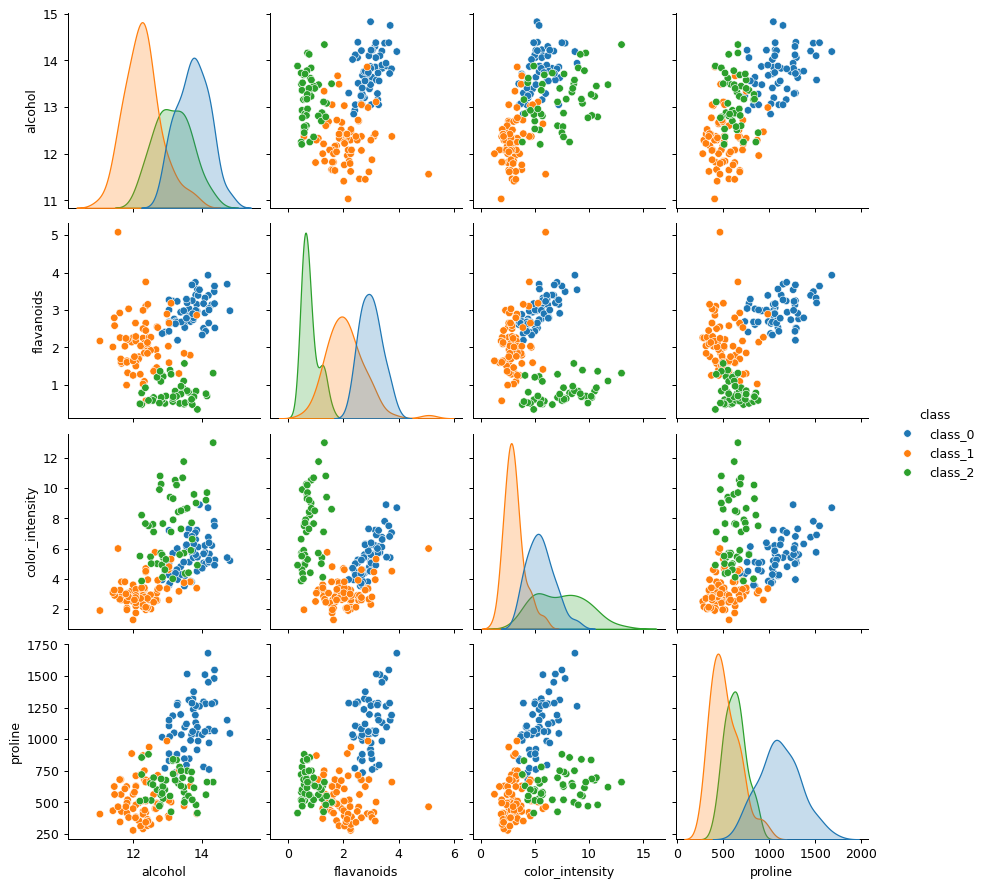

In [4]:
sns.pairplot(df[['alcohol','flavanoids','color_intensity','proline','class']], hue='class')
plt.show()

## 3. Train/test split (80/20) and feature scaling

In [5]:
X = df[data.feature_names]
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit on train only (avoids data leakage)
X_test_s = scaler.transform(X_test)

## 4. Train models

In [6]:
log_reg = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_s, y_train)
tree = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_train_s, y_train)
models = {'Logistic Regression': log_reg, 'Decision Tree': tree}

## 5. Evaluation

Logistic Regression
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36

Decision Tree
              precision    recall  f1-score   support

     class_0       1.00      0.92      0.96        12
     class_1       0.88      1.00      0.93        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.96      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36



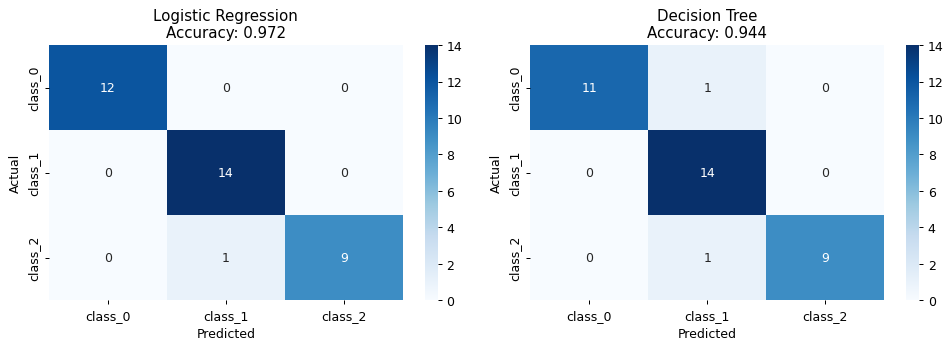

In [7]:
results = {}
for name, model in models.items():
    pred = model.predict(X_test_s)
    results[name] = accuracy_score(y_test, pred)
    print('=' * 50); print(name); print('=' * 50)
    print(classification_report(y_test, pred, target_names=data.target_names))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test_s))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=data.target_names, yticklabels=data.target_names)
    ax.set_title(f'{name}\nAccuracy: {results[name]:.3f}')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.show()

## 6. Decision boundary visualization (2D PCA projection)

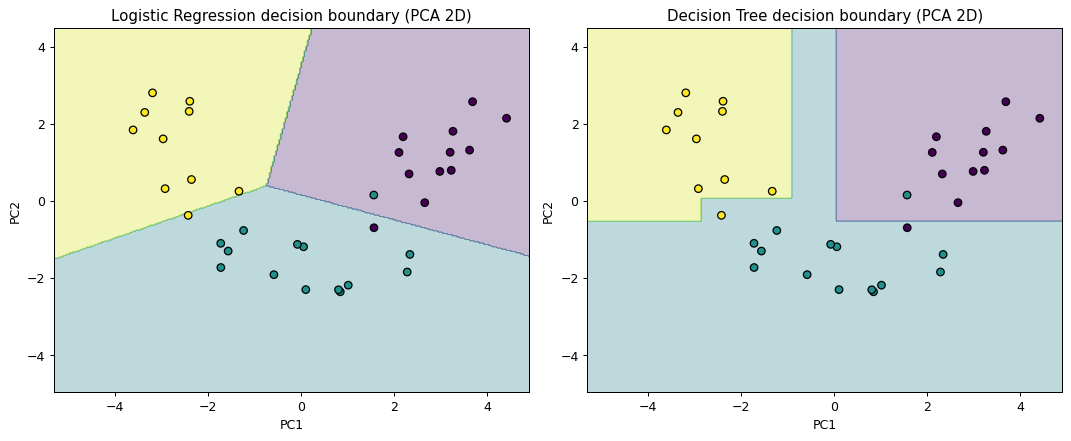

In [8]:
pca = PCA(n_components=2).fit(X_train_s)
Xtr2, Xte2 = pca.transform(X_train_s), pca.transform(X_test_s)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, base) in zip(axes, [('Logistic Regression', LogisticRegression(max_iter=1000)),
                                  ('Decision Tree', DecisionTreeClassifier(max_depth=4, random_state=42))]):
    base.fit(Xtr2, y_train)
    xx, yy = np.meshgrid(np.linspace(Xtr2[:,0].min()-1, Xtr2[:,0].max()+1, 300),
                         np.linspace(Xtr2[:,1].min()-1, Xtr2[:,1].max()+1, 300))
    Z = base.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
    ax.scatter(Xte2[:,0], Xte2[:,1], c=y_test, edgecolor='k', cmap='viridis')
    ax.set_title(f'{name} decision boundary (PCA 2D)')
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
plt.tight_layout(); plt.show()

## 7. Conclusion
Write 3-4 lines here in your own words: which model scored higher, which classes were confused, and why scaling helps Logistic Regression.